# code_155 · Structured records and native language prediction

**Book:** section 30.1. Restart and run all cells using the [dedicated Python 3.12 CPU runtime](../CHAPTER_30_RUNTIME.md), not the earlier chapters' 3.14 environment. Explicit hash-verified public model files must be acquired first; ordinary inference is offline. Use the [guide](../CHAPTER_30_GUIDE.md), [execution evidence](../CHAPTER_30_EXECUTION.md), [asset manifest](../CHAPTER_30_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_155). Prerequisites: structured records, classification/probability and Chapter 8's evidence boundaries. Allow two minutes for execution and30–60 minutes to inspect the contracts.

All states, labels and mechanical examples are generated teaching cases, not field decisions or private records. Named local checkpoints are actually called where declared. No Jev hosted call, account spending or external action occurs. Original typed heads are not named-model substitutes. Output shape, factual correctness, probability calibration and authority to act remain separate questions. Source/development/calibration/final roles are declared locally; generated-instance novelty is not a guarantee of a novel task prior. Neural inference is explicit one-thread CPU float32. The literature cutoff remains18 October 2026.


In [1]:
import platform,time,json,copy,hashlib,sys,warnings
from pathlib import Path
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3955);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3955;rng=np.random.default_rng(SEED);DISCLOSED_WARNINGS=[]
def render_warning(message,category,filename,lineno,file=None,line=None):
    location=filename.split('site-packages/')[-1] if 'site-packages/' in filename else 'code_155'
    DISCLOSED_WARNINGS.append({'category':category.__name__,'message':str(message)})
    print(f'{location}:{lineno}: {category.__name__}: {message}',file=file or sys.stderr)
warnings.showwarning=render_warning
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}
def parameter_digest(network):
    digest=hashlib.sha256()
    for parameter in network.parameters():digest.update(parameter.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


{'python': '3.12.13', 'numpy': '2.5.3', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.1', 'threadpoolctl': '3.7.0', 'torch': '2.8.0'}
CPU: Darwin arm64 seed: 3955


<a id="record-to-language-prediction"></a>
 ## Ask an actual instruction model a bounded structured question
 Twenty-four generated member states contain crack width in millimetres, corrosion percentage and inspection age in days. An explicit constructed rule defines routine/soon/urgent labels. This is not an engineering standard or a field-risk estimate. Actual SmolLM2-135M-Instruct receives a JSON state and rule in a chat-template prompt, with no target labels or few-shot examples. Compare greedy free generation on 12 states with projection of the actual next-token logits onto three allowed one-token answers A/B/C on all 24 states. The latter always produces an allowed label by construction; it need not be factually correct or calibrated. Report the original vocabulary probability mass retained by that projection, rather than pretending renormalized choice probabilities describe the entire language model output distribution.


All declared model/config/tokenizer hashes verified; inference is offline.


tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


W1021 14:13:05.937000 54484 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


,truth,free_generation,projected_choice
0,A,A,A
1,B,A,A
2,C,A,A
3,A,A,A
4,B,A,A
5,C,A,A
6,A,A,A
7,B,A,A
8,C,A,A
9,A,A,A


Conditional-label accuracy: 0.3333333333333333 retained vocabulary mass: 0.22754280269145966


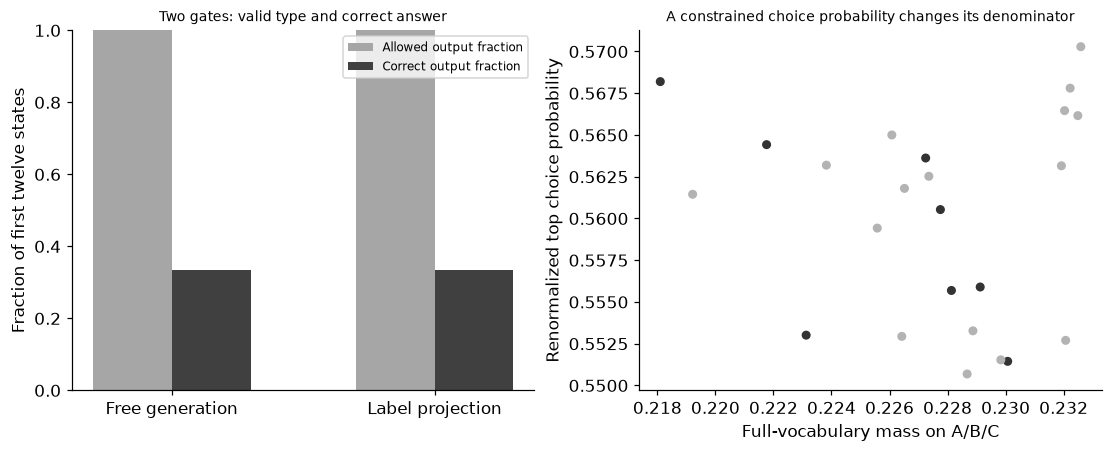

In [2]:
import os,importlib.metadata
ASSET_ROOT=next((root for root in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (root/'build/model-cache').is_dir()),Path.cwd().parent)
os.environ['HF_HUB_CACHE']=str(ASSET_ROOT/'build/model-cache');os.environ['HF_HUB_OFFLINE']='1';os.environ['HF_HUB_DISABLE_PROGRESS_BARS']='1';os.environ['TOKENIZERS_PARALLELISM']='false'
ASSETS={'smollm': {'repository': 'HuggingFaceTB/SmolLM2-135M-Instruct', 'revision': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'files': [{'filename': 'README.md', 'bytes': 6772, 'sha256': '4f97533ad95b1b2fea15fbc075c01b94578ebdd7c8138888fa43fa3abd530dc4', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/README.md'}, {'filename': 'config.json', 'bytes': 861, 'sha256': '8eb740e8bbe4cff95ea7b4588d17a2432deb16e8075bc5828ff7ba9be94d982a', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/config.json'}, {'filename': 'generation_config.json', 'bytes': 132, 'sha256': '87b916edaaab66b3899b9d0dd0752727dff6666686da0504d89ae0a6e055a013', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/generation_config.json'}, {'filename': 'merges.txt', 'bytes': 466391, 'sha256': '0b54e8aa4e53d5383e2e4bc635a56b43f9647f7b13832d5d9ecd8f82dac4f510', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/merges.txt'}, {'filename': 'model.safetensors', 'bytes': 269060552, 'sha256': '5af571cbf074e6d21a03528d2330792e532ca608f24ac70a143f6b369968ab8c', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/model.safetensors'}, {'filename': 'special_tokens_map.json', 'bytes': 655, 'sha256': '2b7379f3ae813529281a5c602bc5a11c1d4e0a99107aaa597fe936c1e813ca52', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/special_tokens_map.json'}, {'filename': 'tokenizer.json', 'bytes': 2104556, 'sha256': '9ca9acddb6525a194ec8ac7a87f24fbba7232a9a15ffa1af0c1224fcd888e47c', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/tokenizer.json'}, {'filename': 'tokenizer_config.json', 'bytes': 3764, 'sha256': '4ec77d44f62efeb38d7e044a1db318f6a939438425312dfa333b8382dbad98df', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/tokenizer_config.json'}, {'filename': 'vocab.json', 'bytes': 800662, 'sha256': '82b84012e3add4d01d12ba14442026e49b8cbbaead1f79ecf3d919784f82dc79', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/vocab.json'}], 'licence': 'Apache-2.0'}};MODEL_PATHS={}
for name,model in ASSETS.items():
    for file in model['files']:
        path=ASSET_ROOT/file['cache_relative_path']
        if not path.is_file():raise FileNotFoundError('Explicit model acquisition is required: build/chapter30-runtime/bin/python scripts/acquire_chapter30_models.py')
        blob=path.read_bytes();assert len(blob)==file['bytes'] and hashlib.sha256(blob).hexdigest()==file['sha256']
    MODEL_PATHS[name]=path.parents[len(Path(file['filename']).parts)-1]
print('All declared model/config/tokenizer hashes verified; inference is offline.')

from transformers import AutoTokenizer,AutoModelForCausalLM
from transformers.utils import logging as transformer_logging
transformer_logging.disable_progress_bar()
VERSIONS['transformers']=importlib.metadata.version('transformers')
tokenizer=AutoTokenizer.from_pretrained(MODEL_PATHS['smollm'],local_files_only=True);tokenizer.padding_side='left';tokenizer.pad_token=tokenizer.eos_token
language_model=AutoModelForCausalLM.from_pretrained(MODEL_PATHS['smollm'],local_files_only=True,dtype=torch.float32,attn_implementation='eager').eval()
LABELS=['A','B','C'];label_token_ids=[tokenizer.encode(label,add_special_tokens=False) for label in LABELS];assert all(len(ids)==1 for ids in label_token_ids);label_ids=[ids[0] for ids in label_token_ids]
def render_prompt(content):return tokenizer.apply_chat_template([{'role':'user','content':content}],tokenize=False,add_generation_prompt=True)
def candidate_probabilities(prompts,batch_size=8):
    probabilities=[];allowed_mass=[];token_counts=[]
    for start in range(0,len(prompts),batch_size):
        batch=tokenizer(prompts[start:start+batch_size],return_tensors='pt',padding=True);token_counts.extend(batch['attention_mask'].sum(1).tolist())
        with torch.no_grad():logits=language_model(**batch).logits[:,-1];p=logits[:,label_ids].softmax(-1);mass=logits.softmax(-1)[:,label_ids].sum(-1)
        probabilities.extend(p.numpy());allowed_mass.extend(mass.numpy())
    return np.array(probabilities),np.array(allowed_mass),np.array(token_counts)
RULE='Choose inspection priority from stated measurements only. A means routine: crack width below 0.15 mm, corrosion below 15 percent, and age at most 365 days. C means urgent: crack width at least 0.40 mm OR corrosion at least 15 percent. B means inspect soon: any other case. Apply C before B before A. Return exactly one letter A, B or C; no explanation.'
def make_states(n,start_id=0):
    states=[];truth=[]
    for j in range(n):
        level=j%3
        if level==0:width=rng.uniform(.01,.14);corrosion=rng.uniform(0,10);age=int(rng.integers(1,300))
        elif level==1:width=rng.uniform(.16,.39);corrosion=rng.uniform(0,10);age=int(rng.integers(1,600))
        else:width=rng.uniform(.45,.8);corrosion=rng.uniform(16,25);age=int(rng.integers(1,600))
        state={'crack_width_mm':round(float(width),2),'corrosion_percent':round(float(corrosion),1),'inspection_age_days':age};states.append(state);truth.append(2 if state['crack_width_mm']>=.4 or state['corrosion_percent']>=15 else 1 if state['crack_width_mm']>=.15 or age>365 else 0)
    return states,np.array(truth)

from sklearn.metrics import accuracy_score,log_loss
states,truth=make_states(24);prompts=[render_prompt(RULE+'\nState: '+json.dumps(state,sort_keys=True)) for state in states];weights_before=parameter_digest(language_model);probabilities,allowed_mass,counts=candidate_probabilities(prompts);prediction=probabilities.argmax(1)
free_text=[];free_labels=[]
for prompt in prompts[:12]:
    encoded=tokenizer(prompt,return_tensors='pt')
    with torch.no_grad():generated=language_model.generate(**encoded,max_new_tokens=12,do_sample=False,pad_token_id=tokenizer.eos_token_id)
    text=tokenizer.decode(generated[0,encoded['input_ids'].shape[1]:],skip_special_tokens=True).strip();free_text.append(text);free_labels.append(LABELS.index(text) if text in LABELS else -1)
free_labels=np.array(free_labels);valid=free_labels>=0;free_correct=int(np.sum(free_labels==truth[:12]));one_hot=np.eye(3)[truth];conditional_Brier=float(np.mean(np.sum((probabilities-one_hot)**2,1)))
assert weights_before==parameter_digest(language_model)
assert all(set(state)=={'crack_width_mm','corrosion_percent','inspection_age_days'} for state in states)
np.testing.assert_allclose(probabilities.sum(1),1,atol=1e-6,rtol=0);assert np.all((allowed_mass>=0)&(allowed_mass<=1))
RESULTS.update(final_states=24,free_generation_states=12,greedy_max_new_tokens=12,conditional_label_accuracy=float(accuracy_score(truth,prediction)),conditional_label_Brier=conditional_Brier,conditional_label_log_loss=float(log_loss(truth,probabilities,labels=[0,1,2])),free_valid_outputs=int(valid.sum()),free_correct_outputs=free_correct,free_generation_text=free_text,conditional_projection_valid_outputs=24,allowed_vocabulary_mass_mean=float(allowed_mass.mean()),allowed_vocabulary_mass_min=float(allowed_mass.min()),allowed_vocabulary_mass_max=float(allowed_mass.max()),mean_prompt_tokens=float(counts.mean()),parameters=sum(p.numel() for p in language_model.parameters()),weight_hash_unchanged=True)
display(pd.DataFrame({'truth':[LABELS[k] for k in truth[:12]],'free_generation':free_text,'projected_choice':[LABELS[k] for k in prediction[:12]]}));print('Conditional-label accuracy:',RESULTS['conditional_label_accuracy'],'retained vocabulary mass:',RESULTS['allowed_vocabulary_mass_mean'])
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(2);axes[0].bar(xx-.15,[valid.mean(),1],width=.3,label='Allowed output fraction',color='.65');axes[0].bar(xx+.15,[free_correct/12,float(np.mean(prediction[:12]==truth[:12]))],width=.3,label='Correct output fraction',color='.25');axes[0].set(xticks=xx,xticklabels=['Free generation','Label projection'],ylim=(0,1),ylabel='Fraction of first twelve states',title='Two gates: valid type and correct answer');axes[0].legend(fontsize=8)
axes[1].scatter(allowed_mass,probabilities.max(1),c=np.where(prediction==truth,'.2','.7'),s=24);axes[1].set(xlabel='Full-vocabulary mass on A/B/C',ylabel='Renormalized top choice probability',title='A constrained choice probability changes its denominator');plt.show()


<a id="serialization-and-action-authority"></a>
 ## Keep model judgment and software authority separate
 The rule, field names and units are part of the prediction specification. No private notes, identifiers or later inspection findings enter the state. Keys are serialized deterministically here, but changing their order need not leave a language model's probabilities invariant. A valid projected label is produced by an application constraint, not proof that the model follows the numeric rule. The retained vocabulary mass exposes information discarded when probabilities are normalized over only three labels. These numbers concern this small checkpoint, explicit prompt and generated task; they are not a universal comparison of language models and numerical estimators. Downstream software still owns action thresholds and review requirements.


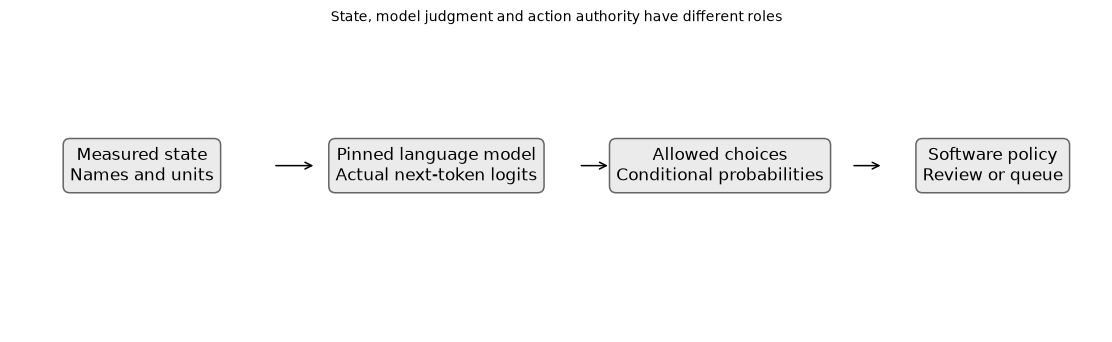

In [3]:
fig,ax=plt.subplots(figsize=(10,3));ax.axis('off');nodes=[(.12,.55,'Measured state\nNames and units'),(.39,.55,'Pinned language model\nActual next-token logits'),(.65,.55,'Allowed choices\nConditional probabilities'),(.90,.55,'Software policy\nReview or queue')]
for xx,yy,label in nodes:ax.text(xx,yy,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=.4','facecolor':'.92','edgecolor':'.4'})
for left,right in [(.24,.28),(.52,.55),(.77,.80)]:ax.annotate('',xy=(right,.55),xytext=(left,.55),xycoords='axes fraction',arrowprops={'arrowstyle':'->'})
ax.set_title('State, model judgment and action authority have different roles');plt.show()
assert len(states)==24 and len(free_text)==12 and 0<=RESULTS['conditional_label_accuracy']<=1


In [4]:
summary={'example_id':'code_155','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual pinned instruction-LLM prediction from bounded generated states', 'units and explicit choice-rule serialization', 'free generation versus conditional allowed-label projection', 'syntax correctness and probability mass measured separately', 'frozen weights and evidence-only field handling'],'results':RESULTS,'disclosed_warnings':DISCLOSED_WARNINGS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual pinned instruction-LLM prediction from bounded generated states", "units and explicit choice-rule serialization", "free generation versus conditional allowed-label projection", "syntax correctness and probability mass measured separately", "frozen weights and evidence-only field handling"], "disclosed_warnings": [{"category": "TqdmWarning", "message": "IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html"}], "elapsed_seconds": 3.75, "example_id": "code_155", "hardware": "Darwin arm64 CPU", "results": {"allowed_vocabulary_mass_max": 0.23259232938289642, "allowed_vocabulary_mass_mean": 0.22754280269145966, "allowed_vocabulary_mass_min": 0.21809974312782288, "conditional_label_Brier": 0.7721142655496035, "conditional_label_accuracy": 0.3333333333333333, "conditional_label_log_loss": 1.2988299131393433, "conditional_projection_valid_outputs": 24, "final_states":